# CS 3110/5110: Data Privacy
## In-Class Exercise, week of 10/12/2026

In [1]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)

# Sens must be L1 sens of vector
def laplace_mech_vec(vec, sensitivity, epsilon):
    return [v + np.random.laplace(loc=0, scale=sensitivity / epsilon) for v in vec]

def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)

# Sens must be L2 sens of vector
# Or L1, but thas worse
def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon) for v in vec]

def pct_error(orig, priv):
    return np.abs(orig - priv)/orig * 100.0

adult = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv')
retail = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/retail.csv')

## Question 1

Implement the Gaussian mechanism for $(\epsilon, \delta)$-differential privacy.

In [2]:
# YOUR CODE HERE
def gaussian_mech(v, sensitivity, epsilon, delta):
    # laplace return v + random.laplace(loc=0, scale=sensitivity/epsilon)
    sigma_squared = 2 * sensitivity ** 2 * np.log(1.25 / delta) / (epsilon ** 2)
    return v + np.random.normal(loc=0, scale = np.sqrt(sigma_squared))

# Delta should be very small
gaussian_mech(len(adult), sensitivity=1, epsilon=1, delta=1e-5) #delta = 0.00001

32558.20923323119

In [3]:
# TEST CASE

results = [gaussian_mech(len(adult[adult['Age'] > 50]), 1, 1.0, 10e-5) for _ in range(100)]
errors = [pct_error(len(adult[adult['Age'] > 50]), r) for r in results]
print('mean error:', np.mean(errors))

assert np.mean(errors) > 0
assert np.mean(errors) < 2

mean error: 0.05828692325995103


## Question 2

How do the Laplace and Gaussian mechanisms compare in terms of relative error on the query "how many individuals are over 50 years old" with $\epsilon = 1$ and $\delta = 10^{-5}$?



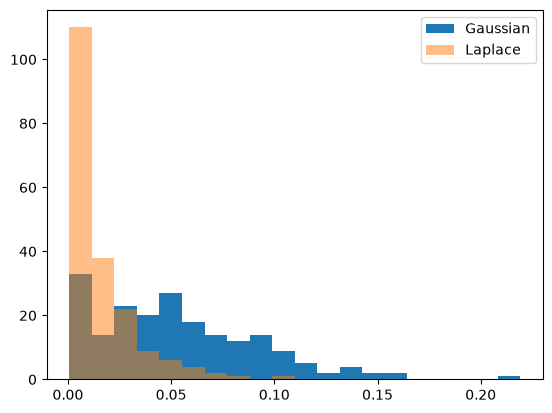

In [4]:
true_answer = len(adult[adult['Age'] > 50])

laplace_answers = [laplace_mech(true_answer, 1, 1) for _ in range(200)]
gaussian_answers = [gaussian_mech(true_answer, 1, 1, 10e-5) for _ in range(200)]

laplace_error = [pct_error(true_answer, a) for a in laplace_answers]
gaussian_error = [pct_error(true_answer, a) for a in gaussian_answers]

_, bins, _ = plt.hist(gaussian_error, bins=20, label='Gaussian')
plt.hist(laplace_error, bins=bins, label='Laplace', alpha=0.5)
plt.legend();

It is more common to get larger errors with Gaussian mech

The Laplace mech gives more accurate answers for query than Gaussian mech with the same epsilon

## Not a Question - Just for reference

[Reference](https://programming-dp.com/chapter6/#the-gaussian-mechanism)

e^epsilon = 2.718281828459045


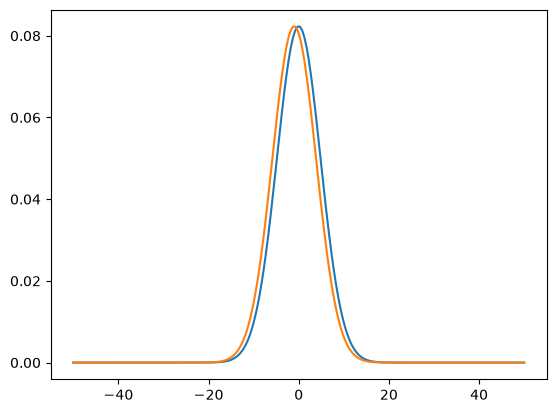

In [5]:
epsilon = 1
sensitivity = 1
delta = 1e-5
sigma_squared = 2 * sensitivity**2 * np.log(1.25 / delta) / (epsilon**2)
sigma = np.sqrt(sigma_squared)

def gauss_pdf(x):
    return 1/(sigma*np.sqrt(2*np.pi)) * np.exp(-(1/2)*(x/sigma)**2)

xs = np.linspace(-50, 50, 200)
ys1 = [gauss_pdf(x) for x in xs]
ys2 = [gauss_pdf(x+1) for x in xs]

plt.plot(xs,ys1)
plt.plot(xs,ys2)

# ratio < e^epsilon should hold
print('e^epsilon =', np.exp(epsilon))
ratios = [(x, y1 / y2) for x, y1, y2 in zip(xs, ys1, ys2)]
#ratios

e^epsilon = 2.718281828459045


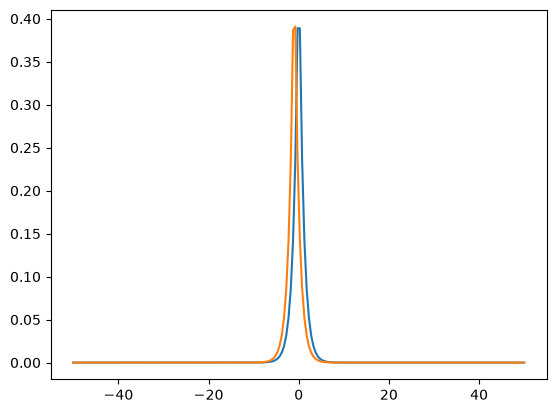

In [6]:
def laplace_pdf(x):
    return (1/2)*epsilon * np.exp(-np.abs(x)*epsilon)

xs = np.linspace(-50, 50, 200)
ys1 = [laplace_pdf(x) for x in xs]
ys2 = [laplace_pdf(x+1) for x in xs]

plt.plot(xs,ys1)
plt.plot(xs,ys2)

# ratio < e^epsilon should hold
print('e^epsilon =', np.exp(epsilon))
ratios = [(x, y1 / y2) for x, y1, y2 in zip(xs, ys1, ys2)]
#ratios

## Question 3

The function `age_cdf` calculates the cumulative distribution function (CDF) of the ages in the adult dataset, expressed as a vector of counts.

What is the **L1 global sensitivity** of `age_cdf`?

Length of CDF vector: 100


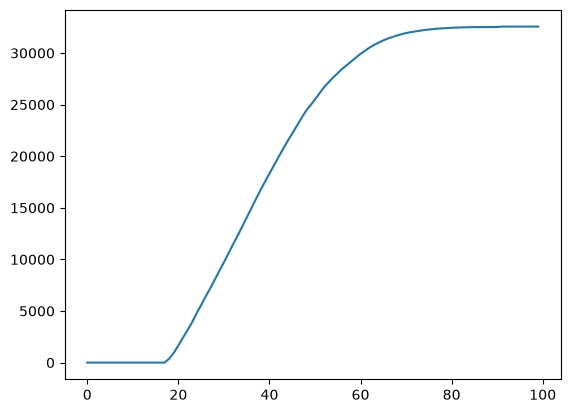

In [7]:
def age_cdf():
    a = adult['Age']
    return [len(a[a < i]) for i in range(100)]
    # Length is 100
    # Each element has sensitivity of 1 (they are counting queries)
    # L1 sens is 1 + 1 + ... + 1, 100 times = 100 * 1 = 100
    # L1 sens is 100

# Can't use parallel comp here, every count uses both people > and <= 40

# Better way than adding noise to different Ls

plt.plot(age_cdf());
print('Length of CDF vector:', len(age_cdf()))

The L1 sens is 100, each element is a counting query with sens 1, and there are 100 elements

## Question 4

What is the **L2 global sensitivity** of `age_cdf`?

The L2 sens is sqrt(100 * 1 ^ 2), each element is a counting query with sens 1, and there are 100 elements, the L2 sens is 10

## Question 5

Use the vector-valued Laplace and Gaussian mechanisms to construct noisy versions of the CDF of ages. **Be sure to use the right sensitivity!**

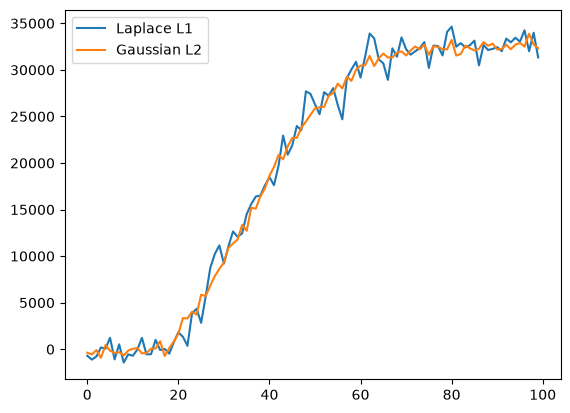

In [8]:
def laplace_cdf(epsilon):
    # Use laplace_mech_vech with L1 sens
    l1_sens = 100
    return laplace_mech_vec(age_cdf(), sensitivity=l1_sens, epsilon=epsilon)

def gaussian_cdf(epsilon, delta):
    l2_sens = np.sqrt(100 * 1 ** 2)
    return gaussian_mech_vec(age_cdf(), sensitivity=l2_sens, epsilon=epsilon, delta=delta)


plt.plot(laplace_cdf(0.1), label='Laplace L1');
plt.plot(gaussian_cdf(0.1, 1e-5), label='Gaussian L2');
plt.legend();

When is L2 << L1?

Not when vector is very short

When the vector is long, L2 can be massively less than L1 

L1 grows linearly with length of vector, L2 grows with its sqrt


## Question 6

Use the *regular* (not vector-valued) Laplace mechanism, **with advanced composition**, to construct a noisy CDF of ages.

NotImplementedError: 

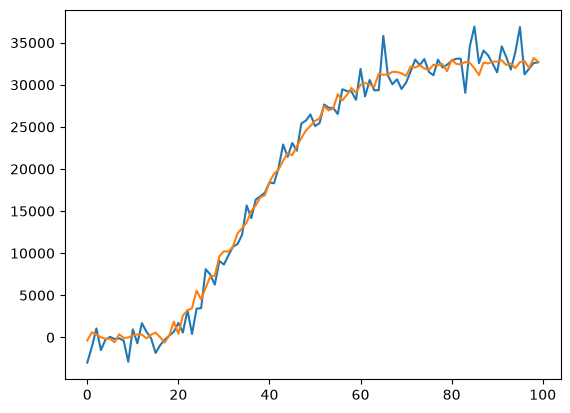

In [9]:
def laplace_cdf_advanced_composition(epsilon, delta):
    # YOUR CODE HERE
    raise NotImplementedError()
    
plt.plot(laplace_cdf(0.1), label='Laplace L1')
plt.plot(gaussian_cdf(0.1, 1e-5), label='Gaussian L2')
plt.plot(laplace_cdf_advanced_composition(0.1, 1e-5), label='Laplace Advanced Comp')
plt.legend();

## Question 7

Consider the retail dataset and the following counting query on it. What is the query's sensitivity?

In [ ]:
def retail_query():
    return len(retail[retail['CustomerID'] == 12748])

retail_query()

YOUR ANSWER HERE

## Question 8

Use contribution bounding to adjust the unit of privacy to be person-level privacy, and implement a differentially private function to return the orders originating from the United Kingdom.

In [ ]:
def bound_contributions(bound):
    # YOUR CODE HERE
    raise NotImplementedError()
    
def dp_retail_query(bound, epsilon):
    # YOUR CODE HERE
    raise NotImplementedError()
    
dp_retail_query(100, 1.0)

In [ ]:
# TEST CASE

results = [dp_retail_query(100, 1.0) for _ in range(100)]
errors = [pct_error(len(retail[retail['Country'] == 'United Kingdom']), r) for r in results]
print('mean error:', np.mean(errors))

assert np.mean(errors) > 20
assert np.mean(errors) < 50